# Train Test Splits, Cross Validation, and Linear Regression

![Lregressions.png](Assets/linearRegr.png)

# Learning Objectives

- Explicarea diferenței dintre supraadaptarea și subadaptarea unui model
- Descrieți compromisurile bias-varianță
- Găsiți împărțirea optimă a seturilor de date de instruire și de testare, validarea încrucișată și complexitatea modelului în funcție de eroare
- Aplicarea unui model de regresie liniară pentru învățarea supravegheată


## Introduction

Vom lucra cu un set de date bazat pe [prețurile locuințelor în Ames, Iowa] (https://www.kaggle.com/c/house-prices-advanced-regression-techniques). Acesta a fost compilat pentru uz educațional pentru a fi o alternativă modernizată și extinsă la binecunoscutul set de date Boston Housing. Această versiune a setului de date a fost completată cu unele valori lipsă pentru comoditate.

Există un număr extins de caracteristici, astfel încât acestea au fost descrise în tabelul de mai jos.

### Predictor

* SalePrice: Prețul de vânzare al proprietății în dolari. 


### Features

<table>
  <tbody>    
    <tr valign="top">
      <td valign="top">
        <ul>
          <li>MoSold: Month Sold</li>
          <li>YrSold: Year Sold</li><br>
          
          <li>SaleType: Type of sale</li>
          <li>SaleCondition: Condition of sale</li><br>

          <li>MSSubClass: The building class</li>
          <li>MSZoning: The general zoning classification</li><br>

          <li>Neighborhood: Physical locations within Ames city limits</li>
          <li>Street: Type of road access</li>
          <li>Alley: Type of alley access</li><br>

          <li>LotArea: Lot size in square feet</li>
          <li>LotConfig: Lot configuration</li>
          <li>LotFrontage: Linear feet of street connected to property</li>
          <li>LotShape: General shape of property</li><br>

          <li>LandSlope: Slope of property</li>
          <li>LandContour: Flatness of the property</li><br>

          <li>YearBuilt: Original construction date</li>
          <li>YearRemodAdd: Remodel date</li>
          <li>OverallQual: Overall material and finish quality</li>
          <li>OverallCond: Overall condition rating</li><br>

          <li>Utilities: Type of utilities available</li>
          <li>Foundation: Type of foundation</li>
          <li>Functional: Home functionality rating</li><br>

          <li>BldgType: Type of dwelling</li>
          <li>HouseStyle: Style of dwelling</li><br>
          
          <li>1stFlrSF: First Floor square feet</li>
          <li>2ndFlrSF: Second floor square feet</li>
          <li>LowQualFinSF: Low quality finished square feet (all floors)</li>
          <li>GrLivArea: Above grade (ground) living area square feet</li>
          <li>TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)</li><br>

          <li>Condition1: Proximity to main road or railroad</li>
          <li>Condition2: Proximity to main road or railroad (if a second is present)</li><br>
          
          <li>RoofStyle: Type of roof</li>
          <li>RoofMatl: Roof material</li><br>

          <li>ExterQual: Exterior material quality</li>
          <li>ExterCond: Present condition of the material on the exterior</li>
          <li>Exterior1st: Exterior covering on house</li>
          <li>Exterior2nd: Exterior covering on house (if more than one material)</li><br><br>
          
        </ul>
      </td>
      
      <td valign="top">
        <ul>
          <li>MasVnrType: Masonry veneer type</li>
          <li>MasVnrArea: Masonry veneer area in square feet</li><br>
          
          <li>WoodDeckSF: Wood deck area in square feet</li>
          <li>OpenPorchSF: Open porch area in square feet</li>
          <li>EnclosedPorch: Enclosed porch area in square feet</li>
          <li>3SsnPorch: Three season porch area in square feet</li>
          <li>ScreenPorch: Screen porch area in square feet</li><br>

          <li>PoolArea: Pool area in square feet</li>
          <li>PoolQC: Pool quality</li>
          <li>Fence: Fence quality</li>
          <li>PavedDrive: Paved driveway</li><br>

          <li>GarageType: Garage location</li>
          <li>GarageYrBlt: Year garage was built</li>
          <li>GarageFinish: Interior finish of the garage</li>
          <li>GarageCars: Size of garage in car capacity</li>
          <li>GarageArea: Size of garage in square feet</li>
          <li>GarageQual: Garage quality</li>
          <li>GarageCond: Garage condition</li><br>

          <li>Heating: Type of heating</li>
          <li>HeatingQC: Heating quality and condition</li>
          <li>CentralAir: Central air conditioning</li>
          <li>Electrical: Electrical system</li><br>
          
          <li>FullBath: Full bathrooms above grade</li>
          <li>HalfBath: Half baths above grade</li><br>
          
          <li>BedroomAbvGr: Number of bedrooms above basement level</li><br>
          
          <li>KitchenAbvGr: Number of kitchens</li>
          <li>KitchenQual: Kitchen quality</li><br>
          
          <li>Fireplaces: Number of fireplaces</li>
          <li>FireplaceQu: Fireplace quality</li><br>
          
          <li>MiscFeature: Miscellaneous feature not covered in other categories</li>
          <li>MiscVal: Value of miscellaneous feature</li><br>
          
          <li>BsmtQual: Height of the basement</li>
          <li>BsmtCond: General condition of the basement</li>
          <li>BsmtExposure: Walkout or garden level basement walls</li>
          <li>BsmtFinType1: Quality of basement finished area</li>
          <li>BsmtFinSF1: Type 1 finished square feet</li>
          <li>BsmtFinType2: Quality of second finished area (if present)</li>
          <li>BsmtFinSF2: Type 2 finished square feet</li>
          <li>BsmtUnfSF: Unfinished square feet of basement area</li>
          <li>BsmtFullBath: Basement full bathrooms</li>
          <li>BsmtHalfBath: Basement half bathrooms</li>
          <li>TotalBsmtSF: Total square feet of basement area</li>
        </ul>
      </td>
    </tr>
    
  </tbody>
</table>


In [6]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler

#from sklearnex import patch_sklearn
#patch_sklearn()

## Question 1

* Importați datele utilizând Pandas și examinați forma. Există 79 de coloane de caracteristici plus predictorul, prețul de vânzare (`SalePrice`). 
* Există trei tipuri diferite: numere întregi (`int64`), numere float (`float64`) și șiruri de caractere (`object`, categoricals). Examinați câte există din fiecare tip de date. 

In [7]:
import pandas as pd
import numpy as np

# Importam datele
filepath = 'Ames_Housing_Sales.csv'
data = pd.read_csv(filepath, sep=',')

print(data.shape)

(1379, 80)


In [8]:
data.dtypes.value_counts()

str        43
float64    21
int64      16
Name: count, dtype: int64

**Raspuns:** setul de date are **1379 de randuri si 80 de coloane** (79 de caracteristici + `SalePrice`). Tipurile de date: **43** coloane text (categoriale), **21** `float64` si **16** `int64`.

*Nota:* in pandas 3 coloanele text au tipul `str` in loc de `object`, de aceea mai jos selectam coloanele categoriale cu `select_dtypes(include=['object', 'string'])`, nu cu `data.dtypes == object`.

## Question 2

După cum s-a discutat în prelegere, o provocare semnificativă, în special atunci când este vorba de date care au mai multe coloane, este să se asigure că fiecare coloană este codificată corect. 

Acest lucru este valabil în special în cazul coloanelor de date care sunt categorice ordonate (ordonate) vs. categorice neordonate. Categoriile neordonate ar trebui să fie codificate o singură dată, însă acest lucru poate crește semnificativ numărul de caracteristici și creează caracteristici care sunt foarte corelate între ele.

Determinați câte caracteristici totale ar fi prezente, în raport cu ceea ce există în prezent, dacă toate caracteristicile șirurilor (obiectelor) sunt codificate o singură dată. Reamintim că numărul total de coloane cu codificare one-hot este `n-1`, unde `n` este numărul de categorii.

In [9]:
# Selectam coloanele text (categoriale)
# In pandas 3 ele au tipul 'str', nu 'object', deci folosim select_dtypes
categorical_cols = data.select_dtypes(include=['object', 'string']).columns

# Valorile lipsa din aceste coloane inseamna "nu exista" (fara alee, fara piscina etc.),
# deci le tratam ca pe o categorie separata
print(data[categorical_cols].isna().sum().loc[lambda s: s > 0])
data[categorical_cols] = data[categorical_cols].fillna('None')

Alley           1297
BsmtCond         426
BsmtExposure     426
BsmtFinType1     426
BsmtFinType2     427
BsmtQual         426
Fence           1114
FireplaceQu      618
MasVnrType       797
MiscFeature     1328
PoolQC          1372
dtype: int64


In [10]:
# Cate coloane noi s-ar crea
num_ohc_cols = (data[categorical_cols]
                .apply(lambda x: x.nunique())
                .sort_values(ascending=False))


# Nu codificam coloanele cu o singura valoare
small_num_ohc_cols = num_ohc_cols.loc[num_ohc_cols>1]

# Numarul de coloane one-hot este cu unu mai mic decat numarul de categorii
small_num_ohc_cols -= 1

# Total coloane suplimentare, daca eliminam coloanele originale
small_num_ohc_cols.sum()

np.int64(215)

**Raspuns:** daca fiecare coloana categoriala cu $n$ categorii devine $n-1$ coloane binare (iar coloana originala se elimina), se adauga **215** coloane, adica setul ar avea in total **294** caracteristici (36 numerice + 43 + 215 = 258 coloane one-hot), fata de 79 in prezent. Cele mai multe provin din coloanele cu multe categorii, cum ar fi `Neighborhood`, `Exterior2nd` si `Exterior1st`.

Valorile lipsa (de exemplu `Alley`, `PoolQC`, `Fence`) au fost tratate ca o categorie in plus (`'None'`), deoarece in acest set de date ele inseamna absenta caracteristicii respective, nu o valoare necunoscuta.

## Question 3

Să creăm un nou set de date în care toate caracteristicile categorice de mai sus vor fi codificate o singură dată. Putem ajusta aceste date și să vedem cum afectează rezultatele.

* Am folosit metoda `.copy()` a cadrului de date pentru a crea o copie complet separată a cadrului de date pentru codificarea one-hot
* Pe acest nou cadru de date, codificați o singură dată fiecare dintre coloanele corespunzătoare și adăugați-o înapoi la cadrul de date. Asigurați-vă că renunțați la coloana originală.
* Pentru datele care nu sunt codificate o singură dată, renunțați la coloanele care sunt șiruri categoriale.

Pentru primul pas, codificarea numerică a categoriilor de șiruri, se poate utiliza `LabelEncoder` sau `DictVectorizer` din Scikit-learn. Cu toate acestea, primul este probabil mai ușor, deoarece nu necesită specificarea unei valori numerice pentru fiecare categorie, iar noi vom codifica oricum toate valorile numerice printr-o singură dată. (Vă puteți gândi la un moment în care `DictVectorizer` ar putea fi preferat?)

In [11]:
# Copie a datelor
data_ohc = data.copy()

# Encoderele
le = LabelEncoder()
ohc = OneHotEncoder()

for col in num_ohc_cols.index:

    # Codificam categoriile text ca numere intregi
    dat = le.fit_transform(data_ohc[col]).astype(int)

    # Eliminam coloana originala din dataframe
    data_ohc = data_ohc.drop(col, axis=1)

    # Codificare one-hot -- intoarce o matrice rara (sparse)
    new_dat = ohc.fit_transform(dat.reshape(-1,1))

    # Nume unice pentru coloanele noi
    n_cols = new_dat.shape[1]
    col_names = ['_'.join([col, str(x)]) for x in range(n_cols)]

    # Construim noul dataframe
    new_df = pd.DataFrame(new_dat.toarray(),
                          index=data_ohc.index,
                          columns=col_names)

    # Adaugam coloanele noi la dataframe
    data_ohc = pd.concat([data_ohc, new_df], axis=1)

In [12]:
# Diferenta de coloane
# OneHotEncoder pastreaza toate cele n categorii (nu n-1), deci diferenta este
# numarul total de categorii minus numarul de coloane originale eliminate
diff = data_ohc.shape[1] - data.shape[1]
print('Coloane adaugate:', diff)
print('Verificare:', num_ohc_cols.sum() - len(num_ohc_cols))

Coloane adaugate: 215
Verificare: 215


**Observatie:** diferenta de coloane este **215**, la fel ca la intrebarea 2. `OneHotEncoder` cu setarile implicite creeaza $n$ coloane (cate una pentru fiecare categorie), dar coloana originala este eliminata, deci castigul net este tot $n-1$ per variabila. Totusi, cele $n$ coloane ale aceleiasi variabile insumeaza mereu 1, deci sunt perfect coliniare cu termenul liber (*dummy variable trap*). Pentru a pastra doar $n-1$ coloane se poate folosi `OneHotEncoder(drop='first')` sau `pd.get_dummies(..., drop_first=True)`.

**Cand ar fi preferat `DictVectorizer`?** Cand datele sunt sub forma de dictionare (de exemplu inregistrari JSON cu chei diferite de la un rand la altul) sau cand vrem sa transformam intr-un singur pas mai multe coloane mixte (numerice + text): `DictVectorizer` face codificarea one-hot direct pe valorile text, lasa valorile numerice neschimbate si pastreaza numele caracteristicilor (`coloana=valoare`).

In [13]:
print(data.shape[1])

# Eliminam coloanele text din dataframe
data = data.drop(num_ohc_cols.index, axis=1)

print(data.shape[1])

80
37


## Question 4

* Creați împărțiri de instruire și de testare ale ambelor seturi de date. Pentru a vă asigura că datele sunt împărțite în același mod, utilizați același `random_state` în fiecare dintre cele două împărțiri.
* Pentru fiecare set de date, ajustați un model de regresie liniară de bază pe datele de antrenament. 
* Calculați eroarea pătratică medie pe seturile de antrenament și de testare pentru modelele respective. Care model produce o eroare mai mică pe datele de testare și de ce?

In [14]:
y_col = 'SalePrice'

# Impartim datele care NU sunt codificate one-hot
feature_cols = [x for x in data.columns if x != y_col]
X_data = data[feature_cols]
y_data = data[y_col]

X_train, X_test, y_train, y_test = train_test_split(X_data, y_data,
                                                    test_size=0.3, random_state=42)
# Impartim datele codificate one-hot (acelasi random_state)
feature_cols = [x for x in data_ohc.columns if x != y_col]
X_data_ohc = data_ohc[feature_cols]
y_data_ohc = data_ohc[y_col]

X_train_ohc, X_test_ohc, y_train_ohc, y_test_ohc = train_test_split(X_data_ohc, y_data_ohc,
                                                    test_size=0.3, random_state=42)

In [15]:
# Verificam ca indicii sunt identici
(X_train_ohc.index == X_train.index).all()

np.True_

In [16]:
LR = LinearRegression()

# Aici salvam erorile
error_df = list()

# Datele fara codificare one-hot
LR = LR.fit(X_train, y_train)
y_train_pred = LR.predict(X_train)
y_test_pred = LR.predict(X_test)

error_df.append(pd.Series({'train': mean_squared_error(y_train, y_train_pred),
                           'test' : mean_squared_error(y_test,  y_test_pred)},
                           name='no enc'))

# Datele cu codificare one-hot
LR = LR.fit(X_train_ohc, y_train_ohc)
y_train_ohc_pred = LR.predict(X_train_ohc)
y_test_ohc_pred = LR.predict(X_test_ohc)

error_df.append(pd.Series({'train': mean_squared_error(y_train_ohc, y_train_ohc_pred),
                           'test' : mean_squared_error(y_test_ohc,  y_test_ohc_pred)},
                          name='one-hot enc'))

# Rezultatele
error_df = pd.concat(error_df, axis=1)
error_df

,no enc,one-hot enc
train,1.131507e+09,3.388514e+08
test,1.372182e+09,1.902841e+09


In [17]:
# RMSE (radacina din MSE) este in dolari, deci mai usor de interpretat
print(np.sqrt(error_df).round(0))
print()
print('Raport MSE test/train:')
print((error_df.loc['test'] / error_df.loc['train']).round(2))
print()
print('Numar de caracteristici: no enc =', X_train.shape[1], '| one-hot =', X_train_ohc.shape[1])
print('Randuri de antrenare:', X_train.shape[0])

        no enc  one-hot enc
train  33638.0      18408.0
test   37043.0      43622.0

Raport MSE test/train:
no enc         1.21
one-hot enc    5.62
dtype: float64

Numar de caracteristici: no enc = 36 | one-hot = 294
Randuri de antrenare: 965


**Raspuns:** 

| | MSE train | MSE test | RMSE test |
|---|---|---|---|
| fara codificare (36 caracteristici) | 1.13e9 | **1.37e9** | ~37 000 \$ |
| one-hot (294 caracteristici) | 0.34e9 | 1.90e9 | ~43 600 \$ |

- Pe **train**, modelul one-hot are eroarea mult mai mica (RMSE ~18 400 \$), deoarece are de 8 ori mai multi parametri si se poate potrivi mai bine pe datele vazute.
- Pe **test**, modelul **fara codificare** are eroarea mai mica. Modelul one-hot are o eroare pe test de **5.6 ori** mai mare decat pe train (fata de 1.2 la modelul simplu): este **supraantrenat (overfitting)** - varianta mare, bias mic.
- Cauze: 294 de caracteristici la doar 965 de randuri de antrenare; multe categorii rare (unele apar doar in setul de test - 10 coloane one-hot sunt zero pe tot setul de antrenare), iar coloanele one-hot sunt coliniare (rangul matricei de antrenare este 232, nu 294), deci coeficientii sunt instabili si invata zgomot. Modelul simplu are bias mai mare, dar varianta mica, si generalizeaza mai bine. Solutia: regularizare (Ridge/Lasso), selectia caracteristicilor sau validare incrucisata.

Rețineți că valorile erorilor privind datele codificate printr-o singură lovitură sunt foarte diferite pentru datele de formare și cele de testare. În special, erorile privind datele de testare sunt mult mai mari. Pe baza lecției, acest lucru se datorează faptului că modelul codificat o singură dată se potrivește prea bine datelor. Vom învăța cum să rezolvăm astfel de probleme în lecția următoare.

## Question 5

Pentru fiecare dintre seturile de date (codificate la cald și necodificate):

* Scalați toate valorile codificate non-hot utilizând una dintre următoarele metode: `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`.
* Comparați eroarea calculată pe seturile de testare

Asigurați-vă că calculați oblicitatea (pentru a decide dacă trebuie efectuată o transformare) și ajustați scalerul pe *NUMai* datele de formare, dar apoi aplicați-l identic atât pe datele de formare, cât și pe cele de testare.

In [18]:
# Dezactivam avertismentul SettingWithCopy
pd.options.mode.chained_assignment = None

In [19]:
# Oblicitatea (skewness) coloanelor float, calculata DOAR pe datele de antrenare
mask = X_train.dtypes == float
float_columns = X_train.columns[mask]

skew_vals = X_train[float_columns].skew().sort_values(ascending=False)
skew_limit = 0.75
skew_cols = skew_vals[skew_vals.abs() > skew_limit].index
print(skew_vals.round(2).to_string())
print()
print(f'Coloane cu |skew| > {skew_limit}:', len(skew_cols), 'din', len(float_columns))
print('Oblicitatea tintei SalePrice (train):', round(y_train.skew(), 2))

MiscVal          26.92
PoolArea         15.78
LotArea          11.50
LowQualFinSF     11.21
3SsnPorch        10.15
ScreenPorch       4.60
BsmtFinSF2        4.47
EnclosedPorch     3.22
LotFrontage       3.14
MasVnrArea        2.49
OpenPorchSF       2.30
BsmtFinSF1        2.01
TotalBsmtSF       1.98
1stFlrSF          1.54
GrLivArea         1.46
WoodDeckSF        1.33
BsmtUnfSF         0.90
GarageArea        0.84
2ndFlrSF          0.77
GarageYrBlt      -0.65

Coloane cu |skew| > 0.75: 19 din 20
Oblicitatea tintei SalePrice (train): 2.11


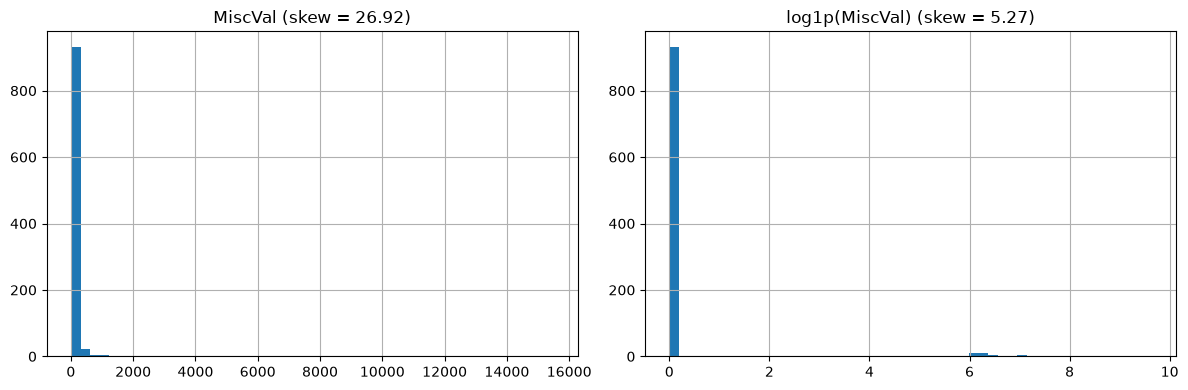

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Exemplu: distributia unei coloane foarte oblice, inainte si dupa log1p
col = skew_vals.index[0]
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(12, 4))
X_train[col].hist(bins=50, ax=ax_before)
ax_before.set(title=f'{col} (skew = {X_train[col].skew():.2f})')
np.log1p(X_train[col]).hist(bins=50, ax=ax_after)
ax_after.set(title=f'log1p({col}) (skew = {np.log1p(X_train[col]).skew():.2f})')
plt.tight_layout()

**Observatie (oblicitate):** 19 din cele 20 de coloane float au $|skew| > 0.75$ (de exemplu `MiscVal` 26.9, `PoolArea` 15.8, `LotArea` 11.5) - au cozi lungi spre dreapta, cu multe valori 0 si cateva valori foarte mari. Pentru aceste coloane aplicam `np.log1p` (care accepta si valoarea 0). Lista coloanelor oblice este calculata doar pe setul de antrenare si aplicata identic pe setul de test. Si tinta `SalePrice` este oblica (2.11); pentru a compara MSE-ul in dolari cu rezultatele anterioare nu o transformam aici.

In [21]:
scalers = {'standard': StandardScaler(),
           'minmax': MinMaxScaler(),
           'maxabs': MaxAbsScaler()}

training_test_sets = {
    'not_encoded': (X_train, y_train, X_test, y_test),
    'one_hot_encoded': (X_train_ohc, y_train_ohc, X_test_ohc, y_test_ohc)}


# Scalam doar coloanele float (cele one-hot nu sunt float in setul original)
# Pornim de fiecare data de la datele originale, ca sa nu scalam de doua ori
mask = X_train.dtypes == float
float_columns = X_train.columns[mask]

# Modelul
LR = LinearRegression()


def evaluate(log_transform):
    # Toate combinatiile codificare x scaler -> eroarea pe test
    errors = {}
    for encoding_label, (_X_train, _y_train, _X_test, _y_test) in training_test_sets.items():
        for scaler_label, scaler in scalers.items():
            trainingset = _X_train.copy()  # copie, ca sa nu scalam de mai multe ori
            testset = _X_test.copy()
            if log_transform:
                # Lista coloanelor oblice e decisa pe train si aplicata identic pe test
                trainingset[skew_cols] = np.log1p(trainingset[skew_cols])
                testset[skew_cols] = np.log1p(testset[skew_cols])
            # Scaler-ul se potriveste (fit) DOAR pe train, apoi se aplica pe ambele
            trainingset[float_columns] = scaler.fit_transform(trainingset[float_columns])
            testset[float_columns] = scaler.transform(testset[float_columns])
            LR.fit(trainingset, _y_train)
            predictions = LR.predict(testset)
            key = encoding_label + ' - ' + scaler_label + 'scaling'
            errors[key] = mean_squared_error(_y_test, predictions)
    return pd.Series(errors)


errors = evaluate(log_transform=False)
errors_log = evaluate(log_transform=True)

results = pd.DataFrame({'MSE fara log': errors, 'MSE cu log1p': errors_log})
results['RMSE fara log'] = np.sqrt(results['MSE fara log'])
results['RMSE cu log1p'] = np.sqrt(results['MSE cu log1p'])
pd.options.display.float_format = '{:,.0f}'.format
results

,MSE fara log,MSE cu log1p,RMSE fara log,RMSE cu log1p
not_encoded - standardscaling,"1,372,182,359","1,317,925,961","37,043","36,303"
not_encoded - minmaxscaling,"1,372,182,359","1,317,925,961","37,043","36,303"
not_encoded - maxabsscaling,"1,372,182,359","1,317,925,961","37,043","36,303"
one_hot_encoded - standardscaling,"8,065,327,607","93,862,382,921","89,807","306,370"
one_hot_encoded - minmaxscaling,"8,065,327,607","93,862,382,921","89,807","306,370"
one_hot_encoded - maxabsscaling,"8,065,327,607","93,862,382,921","89,807","306,370"


**Raspuns:** 

- **Datele fara codificare:** toate cele trei scalere dau **exact aceeasi eroare** (MSE 1.372e9, RMSE ~37 000 \$), identica si cu modelul nescalat de la intrebarea 4. Regresia liniara obisnuita (fara regularizare) este invarianta la transformari liniare ale caracteristicilor: scalarea modifica doar coeficientii ($\beta_j \to \beta_j \cdot s_j$), nu si predictiile. Scalarea conteaza abia la modele regularizate (Ridge, Lasso) sau bazate pe distante (KNN).
- **Transformarea log1p** a coloanelor oblice reduce putin eroarea modelului fara codificare (RMSE de la ~37 000 la ~36 300 \$), pentru ca relatia dintre pret si suprafete devine mai apropiata de una liniara, iar valorile extreme nu mai domina.
- **Datele one-hot:** eroarea pe test este mult mai mare (RMSE ~89 800 \$, iar cu log1p ~306 000 \$) si difera de cea nescalata (~43 600 \$), desi teoretic scalarea nu ar trebui sa schimbe nimic. Motivul este ca matricea este coliniara (rang 232 din 294), deci problema are o infinitate de solutii; `LinearRegression` alege una dintre ele, iar alegerea depinde de scala coloanelor. Modelul este instabil numeric si supraantrenat, deci predictiile pe test variaza foarte mult.
- **Concluzie:** cea mai mica eroare pe test o are modelul **fara codificare, cu log1p + orice scaler**. Pentru a folosi caracteristicile one-hot este nevoie de `drop='first'` si de regularizare.

## Question 6

Reprezentați grafic previziunile față de realitate pentru unul dintre modele.

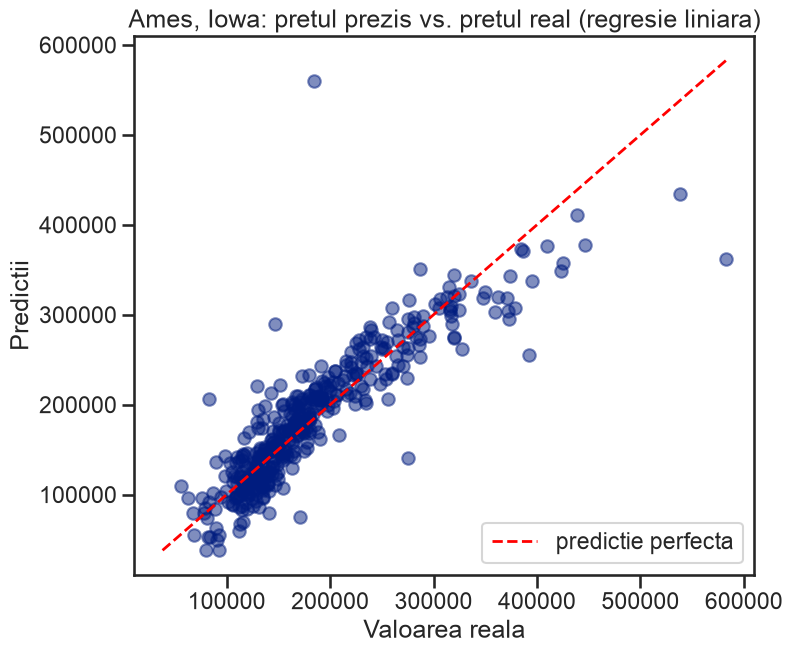

In [22]:
sns.set_context('talk')
sns.set_style('ticks')
sns.set_palette('dark')

fig, ax = plt.subplots(figsize=(8, 7))
# Folosim modelul fara codificare: y_test, y_test_pred
ax.scatter(y_test, y_test_pred, alpha=.5)

# Linia y = x: predictia perfecta
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
ax.plot(lims, lims, color='red', lw=2, ls='--', label='predictie perfecta')
ax.legend()

ax.set(xlabel='Valoarea reala',
       ylabel='Predictii',
       title='Ames, Iowa: pretul prezis vs. pretul real (regresie liniara)');

**Raspuns:** punctele sunt grupate in jurul diagonalei $y = x$ ($R^2 \approx 0.77$ pe test pentru modelul fara codificare), deci modelul surprinde bine tendinta generala. Erorile cresc insa odata cu pretul (heteroscedasticitate): pentru casele sub 150 000 \$ eroarea medie absoluta este ~21 000 \$, iar pentru cele peste 300 000 \$ este ~42 000 \$, iar modelul le **subestimeaza** sistematic (in medie cu ~38 000 \$). Relatia dintre caracteristici si pret nu este perfect liniara, iar `SalePrice` este oblic la dreapta; o transformare logaritmica a tintei (`np.log1p(SalePrice)`) ar reduce acest efect.